# 온라인 쇼핑몰 구매 전환 예측

데이터 감사 → 학습 전용 EDA → 분할 → Pipeline 학습 → 검증 선택 → 테스트 평가 → 예측. 저장소 루트에서 실행합니다. 이 노트북의 학습 셀은 보고서와 모델을 재생성합니다.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from train import load_data, split_data, train
from predict import predict
import joblib
X, y, audit = load_data()
display(pd.Series(audit).to_frame("data audit"))
display(X.head())

,data audit
raw_rows,12330
rows,12205
duplicates_removed,125
conflicting_rows_removed,0
missing_cells,0
positive_rate,0.156329
features,"[Administrative, Administrative_Duration, Info..."
source_url,https://archive.ics.uci.edu/static/public/468/...
raw_sha256,b3055ee355f59134d851d32641183cb4a8b45def7124d2...


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,Feb,1,1,1,1,Returning_Visitor,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,Feb,2,2,1,2,Returning_Visitor,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,Feb,4,1,9,3,Returning_Visitor,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,Feb,3,2,2,4,Returning_Visitor,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,Feb,3,3,1,4,Returning_Visitor,True


## 분할과 특성 분포

60/20/20 층화 분할을 수행합니다. 원본 행 중복과 같은 입력의 상충 타깃은 분할 전에 제거합니다. EDA에는 학습 데이터만 사용합니다.

In [2]:
Xtr, Xv, Xt, ytr, yv, yt = split_data(X, y)
display(pd.DataFrame({"rows": [len(Xtr),len(Xv),len(Xt)], "positive_rate": [ytr.mean(),yv.mean(),yt.mean()]}, index=["train","validation","test"]))
display(Xtr.describe(include="all").T)

,rows,positive_rate
train,7323,0.156357
validation,2441,0.156084
test,2441,0.156493


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Administrative,7323.0,NaN,NaN,NaN,2.360508,3.367832,0.0,0.0,1.0,4.0,27.0
Administrative_Duration,7323.0,NaN,NaN,NaN,83.189051,182.205375,0.0,0.0,9.0,95.3,3398.75
Informational,7323.0,NaN,NaN,NaN,0.508944,1.283293,0.0,0.0,0.0,0.0,24.0
Informational_Duration,7323.0,NaN,NaN,NaN,34.281107,140.13711,0.0,0.0,0.0,0.0,2549.375
ProductRelated,7323.0,NaN,NaN,NaN,31.98812,44.634498,0.0,8.0,18.0,38.0,705.0
ProductRelated_Duration,7323.0,NaN,NaN,NaN,1208.663839,1962.53821,0.0,194.625,612.625,1489.848611,63973.52223
BounceRates,7323.0,NaN,NaN,NaN,0.020446,0.045714,0.0,0.0,0.002778,0.016573,0.2
ExitRates,7323.0,NaN,NaN,NaN,0.041737,0.046535,0.0,0.014286,0.025,0.05,0.2
SpecialDay,7323.0,NaN,NaN,NaN,0.062515,0.199829,0.0,0.0,0.0,0.0,1.0
Month,7323,10,May,2007,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 학습과 검증 선택

스케일링 전후 LogisticRegression, 깊이가 제한된 트리, 과적합 관찰용 무제한 트리를 비교합니다. 쇼핑몰은 RandomForest도 비교합니다. 검증 AP로 모델, 검증 F1으로 임계값을 선택하며 테스트는 선택이 끝난 뒤 평가합니다.

In [3]:
result = train()

{
  "selected_model": "random_forest",
  "threshold": 0.20000000000000004,
  "split_sizes": {
    "train": 7323,
    "validation": 2441,
    "test": 2441
  },
  "test": {
    "accuracy": 0.7218353133961491,
    "precision": 0.31689272503082616,
    "recall": 0.6727748691099477,
    "f1": 0.4308466051969824,
    "roc_auc": 0.7793584035354936,
    "average_precision": 0.3722794896319035
  }
}


,model,convergence_warning,train_accuracy,train_precision,train_recall,train_f1,train_roc_auc,train_average_precision,validation_accuracy,validation_precision,validation_recall,validation_f1,validation_roc_auc,validation_average_precision,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_average_precision
0,dummy,False,0.843643,0.000000,0.000000,0.000000,0.500000,0.156357,0.843916,0.000000,0.000000,0.000000,0.500000,0.156084,0.843507,0.000000,0.000000,0.000000,0.500000,0.156493
1,logistic_unscaled,True,0.843780,0.507937,0.027948,0.052980,0.740681,0.330639,0.843916,0.500000,0.023622,0.045113,0.744484,0.316980,0.843097,0.478261,0.028796,0.054321,0.742451,0.327076
2,logistic_scaled,False,0.844326,0.538462,0.030568,0.057851,0.753119,0.346479,0.842278,0.409091,0.023622,0.044665,0.756395,0.341648,0.844326,0.541667,0.034031,0.064039,0.750171,0.329522
3,tree_depth_3,False,0.843643,0.000000,0.000000,0.000000,0.739316,0.289725,0.843916,0.000000,0.000000,0.000000,0.718414,0.276464,0.843507,0.000000,0.000000,0.000000,0.732173,0.286833
4,tree_depth_5,False,0.848559,0.576271,0.118777,0.196959,0.781638,0.367270,0.840229,0.443038,0.091864,0.152174,0.756277,0.329403,0.835313,0.397959,0.102094,0.162500,0.731996,0.300484
5,tree_depth_8,False,0.858938,0.619658,0.253275,0.359578,0.837988,0.486004,0.831626,0.388060,0.136483,0.201942,0.719258,0.319573,0.827530,0.388571,0.178010,0.244165,0.706805,0.296226
6,tree_unrestricted_diagnostic,False,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.765260,0.256345,0.265092,0.260645,0.561429,0.182662,0.768947,0.274752,0.290576,0.282443,0.574137,0.190857
7,random_forest,False,0.848286,0.972222,0.030568,0.059272,0.884275,0.611111,0.844326,0.666667,0.005249,0.010417,0.776434,0.368365,0.844736,0.800000,0.010471,0.020672,0.779358,0.372279


,threshold,accuracy,precision,recall,f1,roc_auc,average_precision
0,0.10,0.474396,0.221261,0.939633,0.358179,0.776434,0.368365
1,0.15,0.621057,0.269882,0.837270,0.408189,0.776434,0.368365
2,0.20,0.725932,0.314433,0.640420,0.421780,0.776434,0.368365
3,0.25,0.802540,0.372152,0.385827,0.378866,0.776434,0.368365
4,0.30,0.827939,0.406699,0.223097,0.288136,0.776434,0.368365
5,0.35,0.845555,0.517857,0.152231,0.235294,0.776434,0.368365
6,0.40,0.849652,0.640000,0.083990,0.148492,0.776434,0.368365
7,0.45,0.844736,0.555556,0.026247,0.050125,0.776434,0.368365
8,0.50,0.844326,0.666667,0.005249,0.010417,0.776434,0.368365
9,0.55,0.844326,1.000000,0.002625,0.005236,0.776434,0.368365


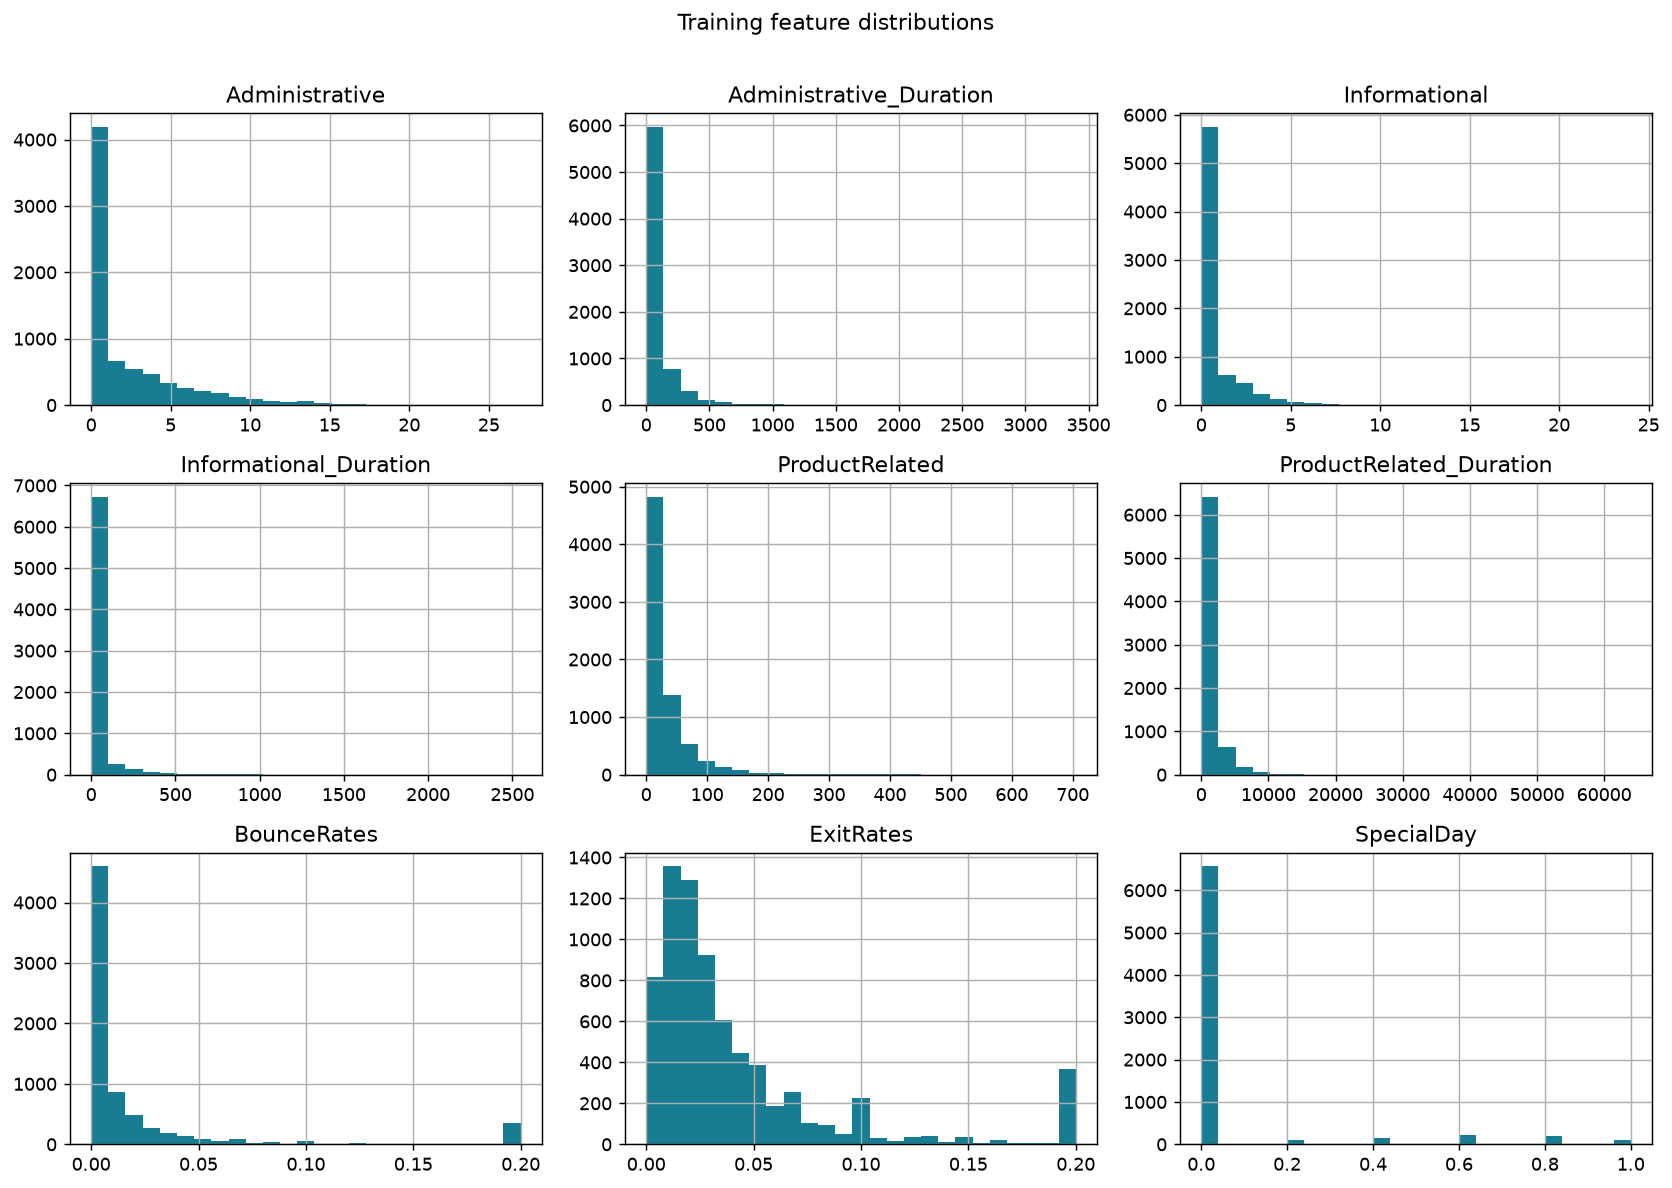

In [4]:
comparison = pd.read_csv("model_comparison.csv")
display(comparison)
display(pd.read_csv("validation_thresholds.csv"))
display(Image(filename="feature_distributions.png"))

## 혼동 행렬·정밀도·재현율과 오답

행은 실제, 열은 예측입니다. 정밀도는 양성 예측의 적중 비율, 재현율은 실제 양성을 찾아낸 비율입니다. 불균형 데이터에서 정확도와 양성 탐지 성능을 함께 해석합니다.

,test
accuracy,0.721835
precision,0.316893
recall,0.672775
f1,0.430847
roc_auc,0.779358
average_precision,0.372279


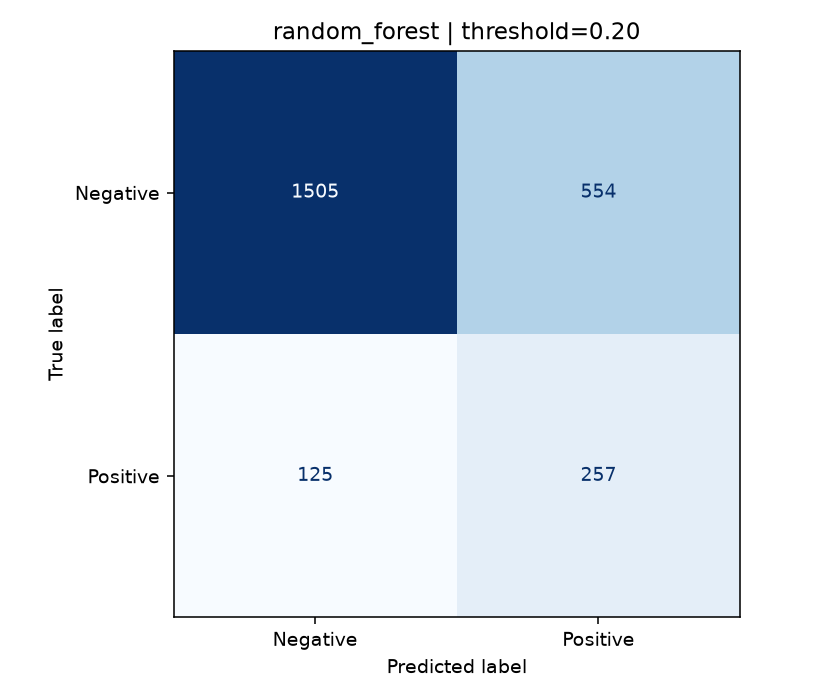

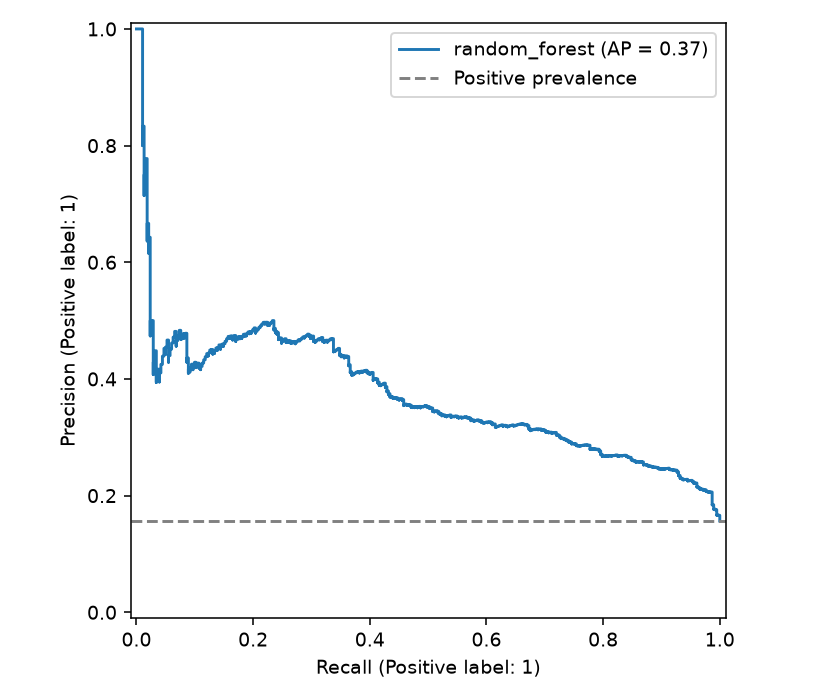

,source_row,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,SpecialDay,...,Browser,Region,TrafficType,VisitorType,Weekend,actual,probability,predicted,error_type,confidence
0,10615,0,0.000000,0,0.0,3,71.166667,0.066667,0.083333,0.0,...,2,1,3,Returning_Visitor,False,1,0.011696,0,FN,0.988304
1,7600,0,0.000000,0,0.0,3,0.000000,0.200000,0.200000,0.0,...,2,1,11,Returning_Visitor,False,1,0.012600,0,FN,0.987400
2,2950,0,0.000000,0,0.0,22,355.666667,0.047619,0.051429,0.8,...,2,3,4,Returning_Visitor,False,1,0.026788,0,FN,0.973212
3,11798,0,0.000000,0,0.0,6,81.750000,0.000000,0.066667,0.0,...,2,1,3,Returning_Visitor,False,1,0.030350,0,FN,0.969650
4,7180,0,0.000000,0,0.0,9,153.200000,0.020000,0.060000,0.0,...,2,7,13,Returning_Visitor,False,1,0.041368,0,FN,0.958632
5,8106,2,256.500000,0,0.0,10,117.250000,0.110714,0.130952,0.0,...,2,7,11,Returning_Visitor,True,1,0.071829,0,FN,0.928171
6,9042,5,175.916667,0,0.0,12,276.250000,0.013333,0.046667,0.0,...,2,1,3,Returning_Visitor,False,1,0.072220,0,FN,0.927780
7,4623,2,58.000000,0,0.0,6,245.000000,0.000000,0.028571,1.0,...,2,3,3,Returning_Visitor,True,1,0.073442,0,FN,0.926558
8,7497,0,0.000000,0,0.0,3,62.400000,0.000000,0.050000,0.0,...,1,8,3,New_Visitor,False,1,0.076011,0,FN,0.923989
9,2785,0,0.000000,0,0.0,25,319.333333,0.016667,0.036667,0.0,...,5,5,1,Returning_Visitor,False,1,0.080011,0,FN,0.919989


In [5]:
display(pd.Series(result["test"]).to_frame("test"))
display(Image(filename="confusion_matrix.png"))
display(Image(filename="precision_recall.png"))
display(pd.read_csv("misclassified.csv").head(10))

## 특성 중요도와 해석

검증 데이터에서 원본 열을 8회 섞었을 때 AP 하락량을 측정합니다. 모델이 의존하는 예측 연관성으로 해석하며, 인과 효과로 해석하지 않습니다.

,feature,mean_ap_decrease,std_ap_decrease
0,Month,0.061353,0.008163
1,ProductRelated_Duration,0.035559,0.008418
2,ExitRates,0.031731,0.010063
3,VisitorType,0.023585,0.005156
4,BounceRates,0.011415,0.005353
5,ProductRelated,0.009963,0.010112
6,TrafficType,0.008523,0.004306
7,Administrative,0.004823,0.008622
8,Region,0.003829,0.002300
9,OperatingSystems,0.000988,0.001709


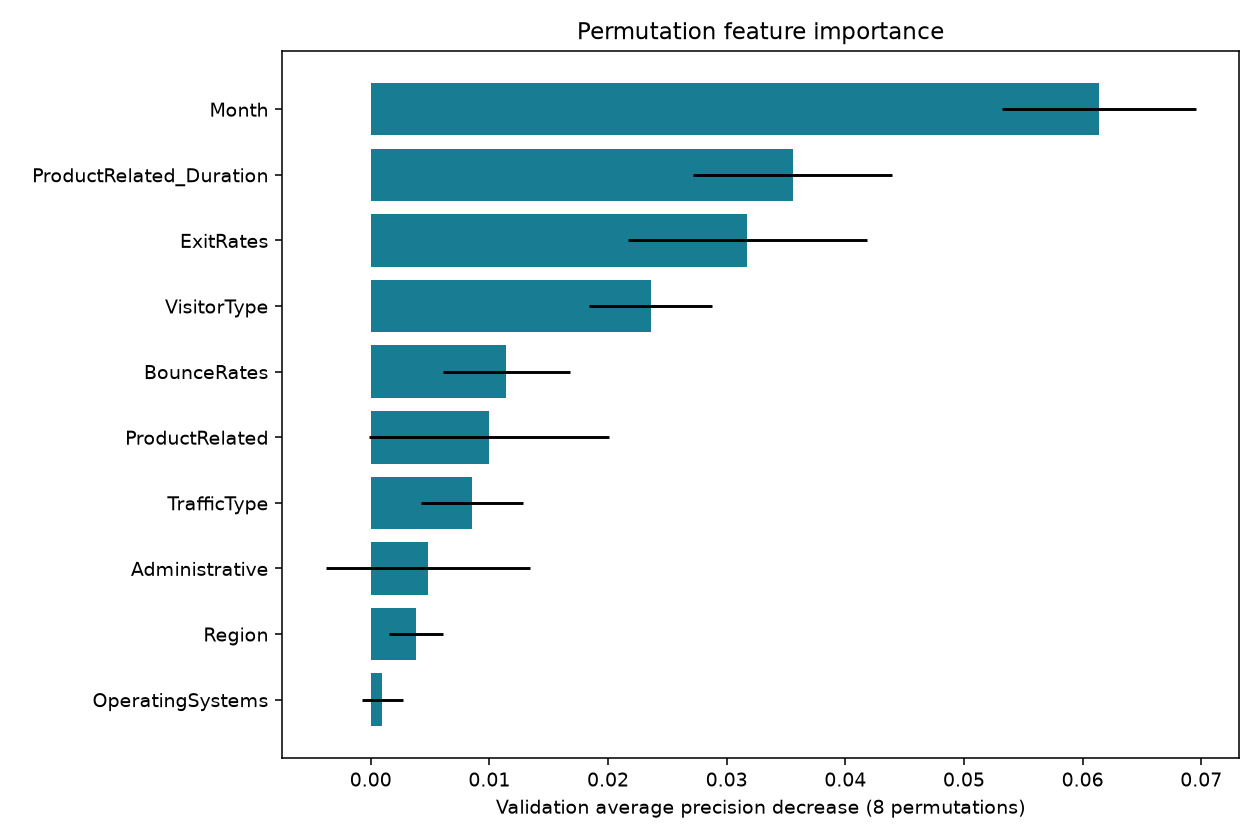

In [6]:
display(pd.read_csv("feature_importance.csv"))
display(Image(filename="feature_importance.png"))

## 성분 또는 행동 입력으로 예측

JSON 예제에서 값을 수정하여 다시 실행합니다. 학습 범위를 벗어나는 숫자는 결과에 표시됩니다.

In [7]:
sample = json.loads(Path("sample_input.json").read_text(encoding="utf-8"))
bundle = joblib.load("model.joblib")
display(sample)
display(predict(sample, bundle))

{'Administrative': 0,
 'Administrative_Duration': 0.0,
 'Informational': 0,
 'Informational_Duration': 0.0,
 'ProductRelated': 10,
 'ProductRelated_Duration': 126.8333333,
 'BounceRates': 0.04,
 'ExitRates': 0.06,
 'SpecialDay': 0.0,
 'Month': 'May',
 'OperatingSystems': '2',
 'Browser': '5',
 'Region': '1',
 'TrafficType': '1',
 'VisitorType': 'Returning_Visitor',
 'Weekend': 'False'}

{'label': '미구매 예상',
 'prediction': 0,
 'positive_probability': 0.023380791282041513,
 'threshold': 0.20000000000000004,
 'outside_training_range': []}

## 종합 평가

데이터 출처와 이용 조건은 DATA_SOURCES.md를 참고하세요. 모델 확률은 보정하지 않았으며 이 결과는 오프라인 교육용 실험입니다.

In [8]:
display(Markdown(Path("evaluation.md").read_text(encoding="utf-8")))

# 온라인 쇼핑몰 구매 전환 성능 평가서

## 문제와 데이터
양성은 **구매(Revenue=True)**입니다. 원본 12,330행에서 입력·타깃이 동일한 중복 125행, 동일 입력의 상충 타깃 0행을 제거해 12,205행을 사용했습니다. 결측 셀은 0개, 양성 비율은 15.63%입니다. 원본 인덱스와 분할은 `split_manifest.csv`, 원본 파일 SHA-256은 `metrics.json`에 기록했습니다.

## 평가 설계
`random_state=42`로 양성 비율을 유지하여 학습/검증/테스트를 60/20/20으로 분리했습니다. 실제 건수는 {'train': 7323, 'validation': 2441, 'test': 2441}입니다. 스케일러·결측 대체·인코더는 Pipeline 안에서 학습 세트로만 적합합니다. EDA도 학습 세트만 사용합니다.
모델은 검증 **Average Precision(AP)** 최대값으로 선택하고, 선택 모델의 임계값은 검증 F1이 최대인 값(0.10~0.90, 간격 0.05)으로 정했습니다. 동률이면 큰 임계값을 사용합니다. AP는 불균형 데이터의 순위 품질을 측정하며, 사다리꼴 PR-AUC와 계산이 다릅니다.
최종 선택은 **random_forest**, 임계값은 **0.20**입니다. 테스트 결과는 선택에 사용하지 않았고, 검증 중요도 평가를 위해 최종 모델을 학습+검증으로 재적합하지 않았습니다. 무제한 트리는 과적합 관찰용으로 선택 대상에서 제외했습니다.

## 모델 비교 — 공통 임계값 0.50
| model | train_f1 | validation_f1 | validation_average_precision | test_accuracy | test_f1 |
| --- | --- | --- | --- | --- | --- |
| dummy | 0.0000 | 0.0000 | 0.1561 | 0.8435 | 0.0000 |
| logistic_unscaled | 0.0530 | 0.0451 | 0.3170 | 0.8431 | 0.0543 |
| logistic_scaled | 0.0579 | 0.0447 | 0.3416 | 0.8443 | 0.0640 |
| tree_depth_3 | 0.0000 | 0.0000 | 0.2765 | 0.8435 | 0.0000 |
| tree_depth_5 | 0.1970 | 0.1522 | 0.3294 | 0.8353 | 0.1625 |
| tree_depth_8 | 0.3596 | 0.2019 | 0.3196 | 0.8275 | 0.2442 |
| tree_unrestricted_diagnostic | 1.0000 | 0.2606 | 0.1827 | 0.7689 | 0.2824 |
| random_forest | 0.0593 | 0.0104 | 0.3684 | 0.8447 | 0.0207 |

모든 후보는 같은 분할을 사용합니다. 아래 최종 성능은 조정 임계값을 사용하므로 위 표의 0.50 결과와 다를 수 있습니다. 스케일링 비교는 같은 LogisticRegression 설정에서 수행합니다. 표준화는 각 특성을 학습 평균 0·표준편차 1로 바꾸며, 정규화 제약과 최적화에 영향을 줍니다. 트리는 분기 순서를 사용하므로 스케일링을 생략했습니다.
수렴 경고가 나온 후보: **logistic_unscaled**. 경고가 있는 비표준화 LogisticRegression은 최적화가 완료되지 않은 비교 실험이며, 그 성능을 수렴한 모델의 확정적 한계로 해석하지 않습니다. `model_comparison.csv`의 convergence_warning 열에도 기록했습니다.

## 최종 테스트 성능
| 정확도 | 정밀도 | 재현율 | F1 | ROC-AUC | AP |
| --- | --- | --- | --- | --- | --- |
| 0.7218 | 0.3169 | 0.6728 | 0.4308 | 0.7794 | 0.3723 |

혼동 행렬의 행은 실제, 열은 예측이며 순서는 음성(0), 양성(1)입니다: **TN=1505, FP=554, FN=125, TP=257**.
다수 클래스 기준 모델의 테스트 정확도는 **0.8435**입니다. 최종 정확도가 이보다 낮아도 양성 탐지 F1과 재현율이 개선될 수 있습니다. 이 선택은 매출이나 비용 최적화를 의미하지 않습니다.
정밀도 TP/(TP+FP)는 양성 예측의 적중률, 재현율 TP/(TP+FN)는 실제 양성을 찾아낸 비율입니다. FP는 구매하지 않을 고객에게 캠페인 비용을 사용하는 오류, FN은 잠재 구매자를 놓치는 오류입니다.

![혼동 행렬](confusion_matrix.png)
![정밀도 재현율 곡선](precision_recall.png)

## 과적합과 오답 노트
무제한 트리의 학습 F1=1.0000, 검증 F1=0.2606입니다. 깊이 3·5·8 및 최소 잎 표본 10으로 제한한 트리와 비교해 일반화 차이를 확인합니다.
테스트 오답 679건 전체를 `misclassified.csv`에 저장했습니다. FP/FN, 실제값, 예측값, 확률, 원본 행 번호와 입력 성분/행동을 확인할 수 있습니다. 확신이 큰 오답 5건은 다음과 같습니다.

| source_row | actual | predicted | probability | error_type |
| --- | --- | --- | --- | --- |
| 10615 | 1 | 0 | 0.0117 | FN |
| 7600 | 1 | 0 | 0.0126 | FN |
| 2950 | 1 | 0 | 0.0268 | FN |
| 11798 | 1 | 0 | 0.0303 | FN |
| 7180 | 1 | 0 | 0.0414 | FN |

오답은 추가 확인 대상이며, 관측하지 않은 원인을 단정하지 않습니다. 확률은 보정하지 않은 모델 출력입니다. 이번 테스트로 수정 방향을 정했다면 다음 버전에는 새로운 홀드아웃이 필요합니다.

## 주요 특성과 활용
검증 세트 원본 열을 하나씩 섞었을 때 AP 하락량을 8회 측정했습니다. 음수는 중요도가 안정적이지 않을 수 있음을 뜻하며, 상관된 열은 중요도를 나눠 가질 수 있습니다.

| feature | mean_ap_decrease | std_ap_decrease |
| --- | --- | --- |
| Month | 0.0614 | 0.0082 |
| ProductRelated_Duration | 0.0356 | 0.0084 |
| ExitRates | 0.0317 | 0.0101 |
| VisitorType | 0.0236 | 0.0052 |
| BounceRates | 0.0114 | 0.0054 |

![특성 중요도](feature_importance.png)
상위 특성에 따라 상품 탐색 동선, 상세 페이지 정보, 재방문 경험을 점검하는 실험 가설을 세울 수 있습니다. 체류 시간을 늘리면 구매가 늘어난다는 인과 결론은 아닙니다. 쿠폰 비용·구매 이익 데이터가 없으므로 매출 개선액이나 ROI를 추정하지 않았습니다.

- `Month`: 계절·캠페인 시기별 구매 패턴의 차이를 점검하되, 월이 중요하다는 결과는 시간 변화에 취약하다는 신호일 수도 있습니다. 다음 기간 검증을 우선합니다.
- `ProductRelated_Duration`: 상품 탐색이 길어지는 구간의 상세 정보·검색 품질을 점검하고 개선안을 A/B 테스트합니다. 중요도만으로 관계의 방향을 해석하지 않습니다.
- `ExitRates`, `VisitorType`: 이탈이 많은 페이지와 신규·재방문 동선의 차이를 추가 분석합니다. 현재 중요도는 특정 집단의 전환율이 더 높다는 결론을 제공하지 않습니다.

## 예측 시점과 누수 검토
`PageValues`는 거래 가치에서 파생된 지표여서 구매 전 사용 가능성을 입증할 수 없습니다. 기본 모델에서 제외했습니다. 이는 명백한 누수라고 단정한 것이 아니라 보수적인 가용성 판단입니다.
체류 시간, BounceRates, ExitRates도 완성된 세션의 집계입니다. 이 프로젝트는 과거 세션의 구매 여부 분류 실습이며, 실시간 전환 예측 성능을 입증하지 않습니다. 실서비스에서는 구매 이전 시점의 이벤트 스냅샷과 시계열 홀드아웃으로 다시 평가해야 합니다. 월·접속 환경 코드에는 원핫 인코딩을 적용합니다.

## 한계와 후속 실험
단일 무작위 분할이므로 성능 변동과 신뢰구간을 추정하지 않았습니다. 교차검증·반복 분할, 확률 보정, 비용 기반 임계값 선택을 후속 실험으로 권합니다. 마케팅 실행 전 시간순 검증과 A/B 테스트가 필요합니다. 데이터에는 명확한 이벤트 시점이 없어서 이 저장소에서는 시간순 검증을 수행하지 않았습니다.

## 출처와 재현
데이터 출처·저작자·라이선스는 [DATA_SOURCES.md](DATA_SOURCES.md)에 있습니다. `python train.py`로 전체 결과를 재생성합니다. Python 및 라이브러리 버전은 `metrics.json`, 설치 목록은 `requirements-lock.txt`에서 확인합니다.
